In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

df = pd.read_excel("zomato_dummy_dataset.xlsx")

arsalan = df[df["restaurant_name"] == "Arsalan"]
arsalan_happy = arsalan[arsalan["rating"] >= 4]
arsalan_unhappy = arsalan[arsalan["rating"] <= 2]

unhappy_text = " ".join(arsalan_unhappy["review_text"])
happy_text = " ".join(arsalan_happy["review_text"])

dish_words = set()
for dish in arsalan["item_ordered"].unique():
    dish_words.update(dish.lower().split())

custom_stopwords = STOPWORDS.union(dish_words).union({
    "arsalan", "ordered", "order", "time", "kolkata", "item", "food",
    "experience", "meal", "arrived", "arrival", "reached", "received",
    "completely", "entirely", "quite", "way", "got", "something", "now",
    "day", "everything", "will", "go", "feel", "felt"
})

kolkata_df = df[df["city"] == "Kolkata"]

print("Setup complete:", len(df), "rows loaded,", len(arsalan), "Arsalan rows,", len(kolkata_df), "Kolkata rows")

Setup complete: 50000 rows loaded, 2374 Arsalan rows, 9143 Kolkata rows


In [2]:
arsalan = df[df["restaurant_name"] == "Arsalan"]

print(f"Arsalan has {len(arsalan)} orders in the dataset")
print(f"\nThat's {len(arsalan) / len(df) * 100:.1f}% of all orders")
print("\nArsalan's cuisine type:", arsalan["cuisine_type"].unique())
print("\nArsalan's cities:", arsalan["city"].unique())
arsalan.head(3)

Arsalan has 2374 orders in the dataset

That's 4.7% of all orders

Arsalan's cuisine type: <ArrowStringArray>
['Mughlai']
Length: 1, dtype: str

Arsalan's cities: <ArrowStringArray>
['Kolkata']
Length: 1, dtype: str


,order_id,restaurant_name,cuisine_type,city,order_type,item_ordered,item_price_inr,quantity,order_amount_inr,order_date,delivery_time_minutes,order_status,rejection_reason,payment_mode,rating,complaint_category,review_text,reviewer_name
53,ORD000054,Arsalan,Mughlai,Kolkata,Delivery,Seekh Kebab,267.27,2,561.27,2025-10-08,28.4,Delivered,NaN,UPI,5,none,Everything arrived on time and the Seekh Kebab...,Vikram Pillai
77,ORD000078,Arsalan,Mughlai,Kolkata,Delivery,Chicken Rezala,295.35,1,310.12,2026-07-23,40.0,Delivered,NaN,Credit Card,5,none,"Best Chicken Rezala I've had in Kolkata, Arsal...",Ananya Mehta
78,ORD000079,Arsalan,Mughlai,Kolkata,Delivery,Firni,76.32,2,160.27,2025-09-26,35.4,Delivered,NaN,Cash on Delivery,1,taste_issue,"Expected better, the Firni lacked flavour and ...",Riya Gupta


In [3]:
import pandas as pd

df = pd.read_excel("zomato_dummy_dataset.xlsx")

print("Shape (rows, columns):", df.shape)
print("\nColumn names:\n", df.columns.tolist())
print("\nFirst 3 rows:\n", df.head(3))
print("\nMissing values per column:\n", df.isna().sum())

Shape (rows, columns): (50000, 18)

Column names:
 ['order_id', 'restaurant_name', 'cuisine_type', 'city', 'order_type', 'item_ordered', 'item_price_inr', 'quantity', 'order_amount_inr', 'order_date', 'delivery_time_minutes', 'order_status', 'rejection_reason', 'payment_mode', 'rating', 'complaint_category', 'review_text', 'reviewer_name']

First 3 rows:
     order_id  restaurant_name                 cuisine_type     city  \
0  ORD000001      Oh Calcutta                      Bengali  Kolkata   
1  ORD000002     Leopold Cafe  Continental & Multi-cuisine   Mumbai   
2  ORD000003  Saravana Bhavan                 South Indian  Chennai   

  order_type         item_ordered  item_price_inr  quantity  order_amount_inr  \
0   Delivery  Chingri Malai Curry          438.84         2            921.56   
1    Dine-in     Pasta Arrabbiata          340.05         2            714.11   
2   Delivery          Masala Dosa           94.03         1             98.73   

  order_date  delivery_time_minu

In [4]:
# Rating comparison
print("Arsalan's rating distribution:")
print(arsalan["rating"].value_counts().sort_index())

print(f"\nArsalan's average rating: {arsalan['rating'].mean():.2f}")
print(f"Overall average rating (all restaurants): {df['rating'].mean():.2f}")

# Delivery time comparison (only delivered orders, since others have no delivery time)
arsalan_delivered = arsalan[arsalan["order_status"] == "Delivered"]
overall_delivered = df[df["order_status"] == "Delivered"]

print(f"\nArsalan's average delivery time: {arsalan_delivered['delivery_time_minutes'].mean():.1f} minutes")
print(f"Overall average delivery time: {overall_delivered['delivery_time_minutes'].mean():.1f} minutes")

# Rejection rate (only among Delivery-type orders)
arsalan_delivery_orders = arsalan[arsalan["order_type"] == "Delivery"]
overall_delivery_orders = df[df["order_type"] == "Delivery"]

arsalan_rejection_rate = (arsalan_delivery_orders["order_status"] == "Rejected").mean() * 100
overall_rejection_rate = (overall_delivery_orders["order_status"] == "Rejected").mean() * 100

print(f"\nArsalan's rejection rate: {arsalan_rejection_rate:.1f}%")
print(f"Overall rejection rate: {overall_rejection_rate:.1f}%")

Arsalan's rating distribution:
rating
1    196
2    297
3    366
4    700
5    815
Name: count, dtype: int64

Arsalan's average rating: 3.69
Overall average rating (all restaurants): 3.72

Arsalan's average delivery time: 35.1 minutes
Overall average delivery time: 35.3 minutes

Arsalan's rejection rate: 10.3%
Overall rejection rate: 8.5%


In [5]:
arsalan_happy = arsalan[arsalan["rating"] >= 4]
arsalan_unhappy = arsalan[arsalan["rating"] <= 2]

print(f"Happy reviews (4-5 star): {len(arsalan_happy)}")
print(f"Unhappy reviews (1-2 star): {len(arsalan_unhappy)}")

print("\nSample unhappy review:")
print(arsalan_unhappy["review_text"].iloc[0])

print("\nSample happy review:")
print(arsalan_happy["review_text"].iloc[0])

Happy reviews (4-5 star): 1515
Unhappy reviews (1-2 star): 493

Sample unhappy review:
Expected better, the Firni lacked flavour and felt undercooked.

Sample happy review:
Everything arrived on time and the Seekh Kebab tasted fresh and great.


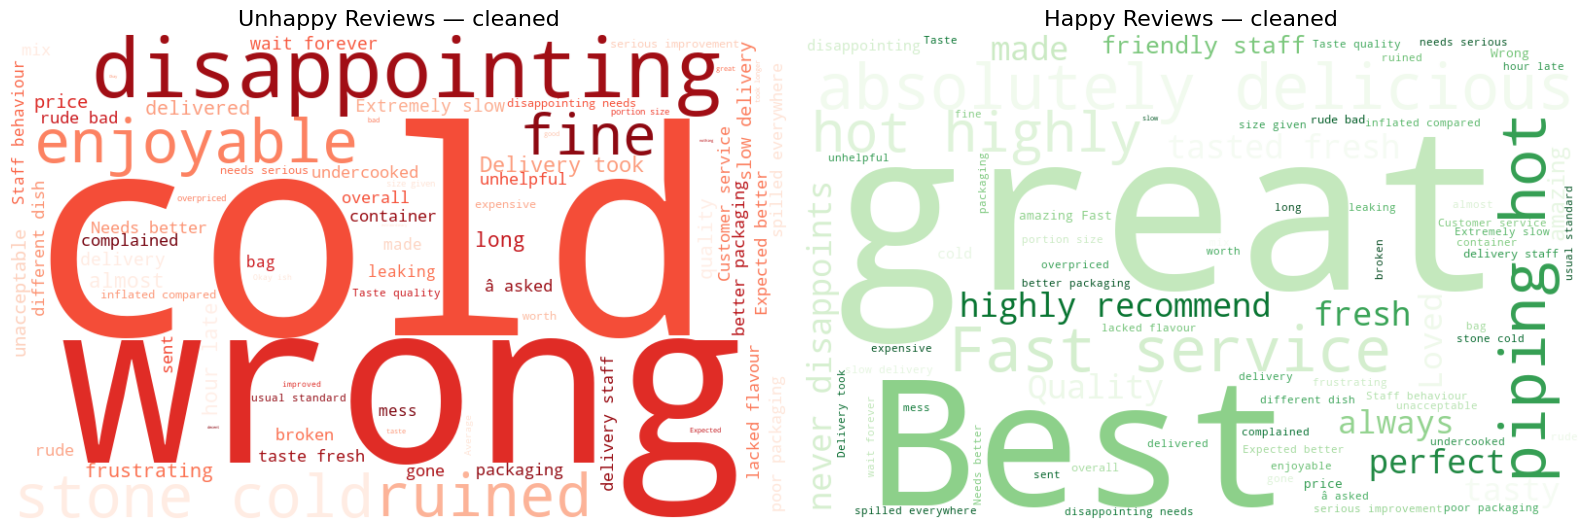

In [6]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

unhappy_text = " ".join(arsalan_unhappy["review_text"])
happy_text = " ".join(arsalan_happy["review_text"])

dish_words = set()
for dish in arsalan["item_ordered"].unique():
    dish_words.update(dish.lower().split())

custom_stopwords = STOPWORDS.union(dish_words).union({
    "arsalan", "ordered", "order", "time", "kolkata", "item", "food",
    "experience", "meal", "arrived", "arrival", "reached", "received",
    "completely", "entirely", "quite", "way", "got", "something", "now",
    "day", "everything", "will", "go", "feel", "felt"
})

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

wc_unhappy = WordCloud(width=800, height=500, background_color="white",
                        colormap="Reds", stopwords=custom_stopwords).generate(unhappy_text)
axes[0].imshow(wc_unhappy, interpolation="bilinear")
axes[0].set_title("Unhappy Reviews — cleaned", fontsize=16)
axes[0].axis("off")

wc_happy = WordCloud(width=800, height=500, background_color="white",
                      colormap="Greens", stopwords=custom_stopwords).generate(happy_text)
axes[1].imshow(wc_happy, interpolation="bilinear")
axes[1].set_title("Happy Reviews — cleaned", fontsize=16)
axes[1].axis("off")

plt.tight_layout()
plt.show()

Arsalan's unhappy reviews — root cause breakdown:

  cold_food: 24.3%  (120 reviews)
  wrong_order: 17.0%  (84 reviews)
  late_delivery: 17.0%  (84 reviews)
  packaging_issue: 10.5%  (52 reviews)
  taste_issue: 10.1%  (50 reviews)
  rude_staff: 9.7%  (48 reviews)
  overpriced: 6.9%  (34 reviews)
  none: 4.3%  (21 reviews)


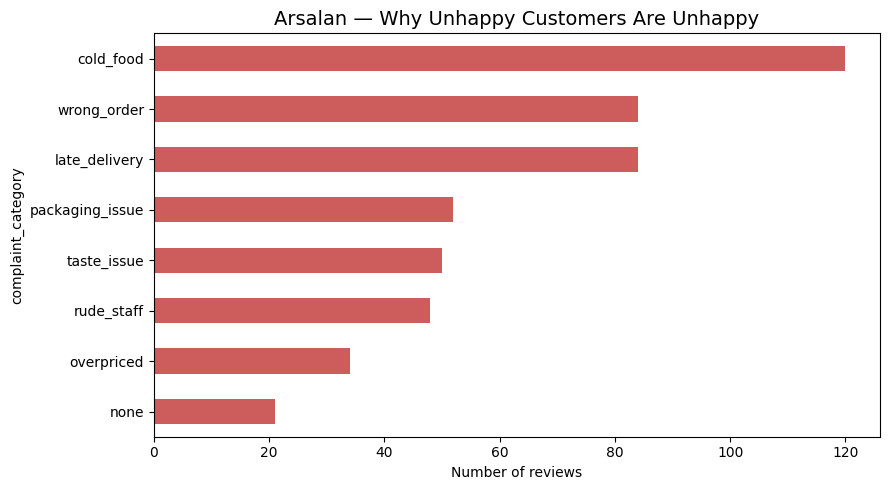

In [7]:
complaint_counts = arsalan_unhappy["complaint_category"].value_counts()
complaint_percent = (complaint_counts / len(arsalan_unhappy) * 100).round(1)

print("Arsalan's unhappy reviews — root cause breakdown:\n")
for category, percent in complaint_percent.items():
    print(f"  {category}: {percent}%  ({complaint_counts[category]} reviews)")

# chart banate hain
plt.figure(figsize=(9, 5))
complaint_counts.plot(kind="barh", color="indianred")
plt.title("Arsalan — Why Unhappy Customers Are Unhappy", fontsize=14)
plt.xlabel("Number of reviews")
plt.gca().invert_yaxis()  # sabse bada reason sabse upar dikhe
plt.tight_layout()
plt.show()

In [8]:
summary = kolkata_df.groupby("restaurant_name").agg(
    avg_rating=("rating", "mean"),
    total_orders=("order_id", "count"),
).round(2)

delivery_only = kolkata_df[kolkata_df["order_type"] == "Delivery"]

rejection_by_restaurant = delivery_only.groupby("restaurant_name")["order_status"].apply(
    lambda x: (x == "Rejected").mean() * 100
).round(2)

summary["rejection_rate_pct"] = summary.index.map(rejection_by_restaurant)

print("Kolkata restaurants — corrected comparison:\n")
print(summary.sort_values("avg_rating"))

Kolkata restaurants — corrected comparison:

                 avg_rating  total_orders  rejection_rate_pct
restaurant_name                                              
Trincas                3.66          1263               12.83
Arsalan                3.69          2374               10.27
Peter Cat              3.70          1800                6.77
Oh Calcutta            3.71          1687                7.90
Flurys                 3.76          2019                5.16


In [9]:
mughlai_group = df[df["cuisine_type"].str.contains("Mughlai", case=False, na=False)]

mughlai_summary = mughlai_group.groupby(["restaurant_name", "city"]).agg(
    avg_rating=("rating", "mean"),
    total_orders=("order_id", "count"),
).round(2)

mughlai_unhappy = mughlai_group[mughlai_group["rating"] <= 2]
cold_food_rate = mughlai_unhappy.groupby("restaurant_name")["complaint_category"].apply(
    lambda x: (x == "cold_food").mean() * 100
).round(1)

mughlai_summary["cold_food_complaint_pct"] = mughlai_summary.index.get_level_values("restaurant_name").map(cold_food_rate)

print("Mughlai-cuisine restaurants across cities:\n")
print(mughlai_summary.sort_values("avg_rating"))

Mughlai-cuisine restaurants across cities:

                         avg_rating  total_orders  cold_food_complaint_pct
restaurant_name city                                                      
Arsalan         Kolkata        3.69          2374                     24.3
Peter Cat       Kolkata        3.70          1800                     23.0
Bademiya        Mumbai         3.72          2202                     21.1
Karims          Delhi          3.73          2137                     23.5


In [10]:
def diagnose(subset_df, label):
    delivered = subset_df[subset_df["order_status"] == "Delivered"]
    delivery_orders = subset_df[subset_df["order_type"] == "Delivery"]
    unhappy = subset_df[subset_df["rating"] <= 2]

    top_complaint = None
    top_complaint_pct = None
    if len(unhappy) > 0:
        counts = unhappy["complaint_category"].value_counts(normalize=True)
        top_complaint = counts.idxmax()
        top_complaint_pct = round(counts.max() * 100, 1)

    return {
        "label": label,
        "total_orders": len(subset_df),
        "avg_rating": round(subset_df["rating"].mean(), 2),
        "avg_delivery_time": round(delivered["delivery_time_minutes"].mean(), 1) if len(delivered) else None,
        "rejection_rate_pct": round((delivery_orders["order_status"] == "Rejected").mean() * 100, 2) if len(delivery_orders) else None,
        "unhappy_pct": round(len(unhappy) / len(subset_df) * 100, 1),
        "top_complaint": top_complaint,
        "top_complaint_pct": top_complaint_pct,
    }

In [11]:
# Level 1: every restaurant
restaurant_rows = [diagnose(df[df["restaurant_name"] == r], r) for r in df["restaurant_name"].unique()]
restaurant_scorecard = pd.DataFrame(restaurant_rows).sort_values("avg_rating")
print("=== RESTAURANT LEVEL ===")
print(restaurant_scorecard.to_string(index=False))

# Level 2: every city
city_rows = [diagnose(df[df["city"] == c], c) for c in df["city"].unique()]
city_scorecard = pd.DataFrame(city_rows).sort_values("avg_rating")
print("\n=== CITY LEVEL ===")
print(city_scorecard.to_string(index=False))

# Level 3: all of India (whole dataset)
print("\n=== ALL INDIA ===")
print(diagnose(df, "All India"))

=== RESTAURANT LEVEL ===
                 label  total_orders  avg_rating  avg_delivery_time  rejection_rate_pct  unhappy_pct top_complaint  top_complaint_pct
               Trincas          1263        3.66               35.5               12.83         22.8 late_delivery               21.9
              Agashiye          1624        3.68               35.8               11.04         20.5     cold_food               20.7
              Bawarchi          2070        3.68               34.9               10.28         20.8 late_delivery               21.3
         Tunday Kababi          2288        3.69               35.0                7.74         20.7     cold_food               19.2
               Arsalan          2374        3.69               35.1               10.27         20.8     cold_food               24.3
        Britannia & Co          1430        3.70               34.3                5.59         19.8     cold_food               20.5
     Murugan Idli Shop          1857 

year_month
2024-11    3.640449
2024-12    3.731959
2025-01    3.733945
2025-02    3.812500
2025-03    3.875000
2025-04    3.604651
2025-05    3.377358
2025-06    3.473684
2025-07    3.672414
2025-08    3.851485
2025-09    3.652632
2025-10    3.526786
2025-11    3.775000
2025-12    3.712871
2026-01    3.628866
2026-02    3.765957
2026-03    3.841584
2026-04    3.522727
2026-05    3.765625
2026-06    3.735632
2026-07    3.887640
2026-08    3.652632
2026-09    3.764151
2026-10    3.595745
Freq: M, Name: rating, dtype: float64


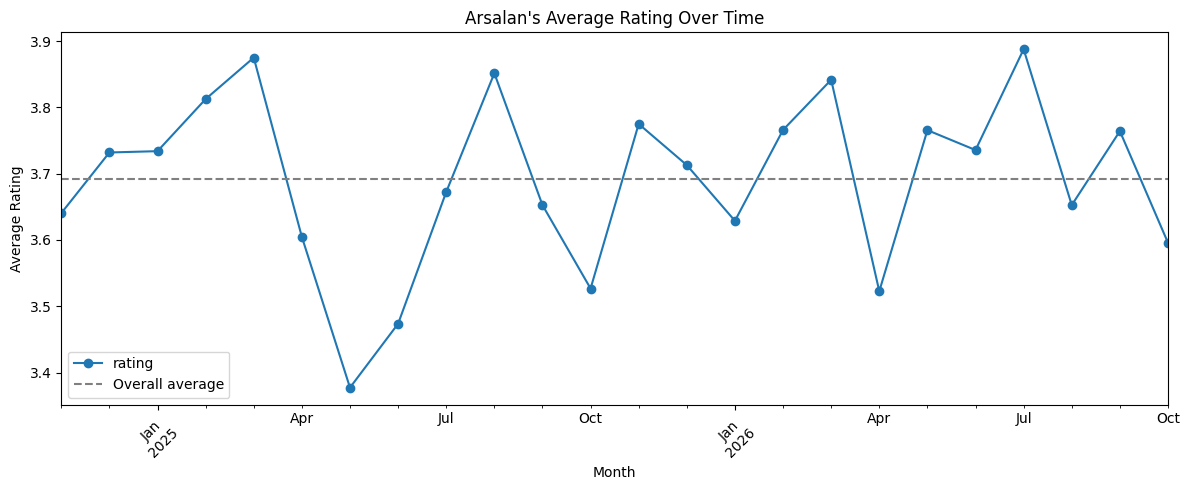

In [12]:
arsalan = arsalan.copy()
arsalan["order_date"] = pd.to_datetime(arsalan["order_date"])
arsalan["year_month"] = arsalan["order_date"].dt.to_period("M")

monthly_rating = arsalan.groupby("year_month")["rating"].mean()

print(monthly_rating)

plt.figure(figsize=(12, 5))
monthly_rating.plot(marker="o")
plt.title("Arsalan's Average Rating Over Time")
plt.xlabel("Month")
plt.ylabel("Average Rating")
plt.axhline(y=arsalan["rating"].mean(), color="gray", linestyle="--", label="Overall average")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Arsalan has 277 rejected/cancelled delivery orders

  Kitchen delay: 16.6%  (46 orders)
  Customer cancelled: 13.7%  (38 orders)
  Item out of stock: 13.0%  (36 orders)
  Weather conditions: 12.6%  (35 orders)
  Restaurant too busy: 12.3%  (34 orders)
  Restaurant closed early: 11.2%  (31 orders)
  Payment failed: 10.8%  (30 orders)
  Address unreachable: 9.7%  (27 orders)


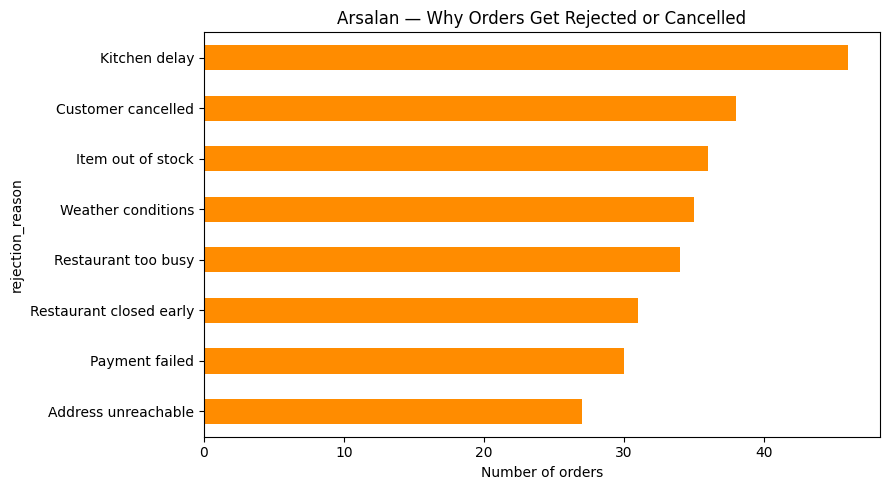

In [13]:
arsalan_delivery = arsalan[arsalan["order_type"] == "Delivery"]
rejected_or_cancelled = arsalan_delivery[arsalan_delivery["order_status"].isin(["Rejected", "Cancelled"])]

reason_counts = rejected_or_cancelled["rejection_reason"].value_counts()
reason_pct = (reason_counts / len(rejected_or_cancelled) * 100).round(1)

print(f"Arsalan has {len(rejected_or_cancelled)} rejected/cancelled delivery orders\n")
for reason, pct in reason_pct.items():
    print(f"  {reason}: {pct}%  ({reason_counts[reason]} orders)")

plt.figure(figsize=(9, 5))
reason_counts.sort_values().plot(kind="barh", color="darkorange")
plt.title("Arsalan — Why Orders Get Rejected or Cancelled")
plt.xlabel("Number of orders")
plt.tight_layout()
plt.show()

            avg_rating  total_orders  unhappy_pct
order_type                                       
Delivery          3.68          1587        20.73
Dine-in           3.71           787        20.84

Delivery — top complaint: cold_food (24.6%)

Dine-in — top complaint: cold_food (23.8%)


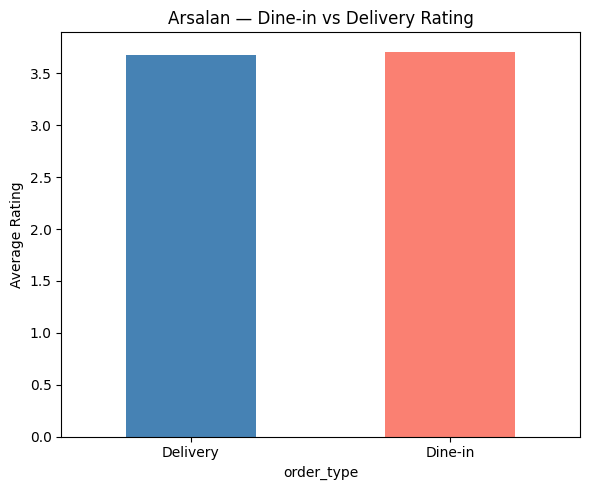

In [14]:
order_type_summary = arsalan.groupby("order_type").agg(
    avg_rating=("rating", "mean"),
    total_orders=("order_id", "count"),
    unhappy_pct=("rating", lambda x: (x <= 2).mean() * 100)
).round(2)

print(order_type_summary)

# Top complaint for each order type separately
for ot in arsalan["order_type"].unique():
    subset = arsalan[(arsalan["order_type"] == ot) & (arsalan["rating"] <= 2)]
    top = subset["complaint_category"].value_counts(normalize=True)
    print(f"\n{ot} — top complaint: {top.idxmax()} ({round(top.max()*100, 1)}%)")

order_type_summary["avg_rating"].plot(kind="bar", color=["steelblue", "salmon"], figsize=(6, 5))
plt.title("Arsalan — Dine-in vs Delivery Rating")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
import re

def detect_complaint(review_text):
    text = review_text.lower()
    keyword_map = {
        "cold_food": ["cold"],
        "late_delivery": ["late", "slow", "took way too long", "unacceptable"],
        "wrong_order": ["wrong", "mix-up", "different dish", "entirely"],
        "rude_staff": ["rude", "unhelpful", "behaviour"],
        "overpriced": ["overpriced", "expensive", "inflated"],
        "packaging_issue": ["packaging", "spilled", "leaking", "broken"],
        "taste_issue": ["didn't taste", "lacked flavour", "undercooked", "disappointing"],
    }
    for category, keywords in keyword_map.items():
        for kw in keywords:
            pattern = r"\b" + re.escape(kw) + r"\b"
            if re.search(pattern, text):
                return category
    return "none"

arsalan_unhappy["my_detected_category"] = arsalan_unhappy["review_text"].apply(detect_complaint)

accuracy = (arsalan_unhappy["my_detected_category"] == arsalan_unhappy["complaint_category"]).mean() * 100
print(f"My detector matches the real answer {accuracy:.1f}% of the time\n")

mismatches = arsalan_unhappy[arsalan_unhappy["my_detected_category"] != arsalan_unhappy["complaint_category"]]
print(f"Got {len(mismatches)} wrong out of {len(arsalan_unhappy)}\n")
print(mismatches[["review_text", "complaint_category", "my_detected_category"]].head(5).to_string(index=False))

My detector matches the real answer 98.8% of the time

Got 6 wrong out of 493

                                                          review_text complaint_category my_detected_category
  Okay-ish, the Seekh Kebab was fine but packaging could be improved.               none      packaging_issue
   Okay-ish, the Fish Kalia was fine but packaging could be improved.               none      packaging_issue
 Okay-ish, the Mutton Korma was fine but packaging could be improved.               none      packaging_issue
Okay-ish, the Mutton Rezala was fine but packaging could be improved.               none      packaging_issue
Okay-ish, the Mutton Rezala was fine but packaging could be improved.               none      packaging_issue


In [16]:
print("=== NATIONAL OVERVIEW (All India) ===\n")
print(f"Total orders: {len(df)}")
print(f"Average rating: {df['rating'].mean():.2f}")

delivered_all = df[df["order_status"] == "Delivered"]
print(f"Average delivery time: {delivered_all['delivery_time_minutes'].mean():.1f} minutes")

delivery_orders_all = df[df["order_type"] == "Delivery"]
national_rejection = (delivery_orders_all["order_status"] == "Rejected").mean() * 100
print(f"National rejection rate: {national_rejection:.2f}%")

unhappy_all = df[df["rating"] <= 2]
print(f"\nUnhappy orders nationally: {len(unhappy_all)} ({len(unhappy_all)/len(df)*100:.1f}%)")

print("\nTop complaints nationally (among unhappy reviews):")
top_complaint_national = (unhappy_all["complaint_category"].value_counts(normalize=True) * 100).round(1)
print(top_complaint_national)

# City-level scorecard, reusing the diagnose() function from before
city_rows = [diagnose(df[df["city"] == c], c) for c in df["city"].unique()]
city_scorecard = pd.DataFrame(city_rows).sort_values("rejection_rate_pct", ascending=False)

print("\n=== CITIES RANKED BY REJECTION RATE (worst first) ===")
print(city_scorecard.to_string(index=False))

=== NATIONAL OVERVIEW (All India) ===

Total orders: 50000
Average rating: 3.72
Average delivery time: 35.3 minutes
National rejection rate: 8.53%

Unhappy orders nationally: 9898 (19.8%)

Top complaints nationally (among unhappy reviews):
complaint_category
cold_food          21.0
late_delivery      20.6
wrong_order        17.8
overpriced          9.5
taste_issue         9.2
packaging_issue     9.2
rude_staff          9.2
none                3.5
Name: proportion, dtype: float64

=== CITIES RANKED BY REJECTION RATE (worst first) ===
    label  total_orders  avg_rating  avg_delivery_time  rejection_rate_pct  unhappy_pct top_complaint  top_complaint_pct
  Chennai          3824        3.72               35.4               10.94         19.9 late_delivery               20.9
   Mumbai          5580        3.72               35.4               10.45         19.8 late_delivery               22.2
   Jaipur          3496        3.77               35.4                9.64         18.2     cold_f

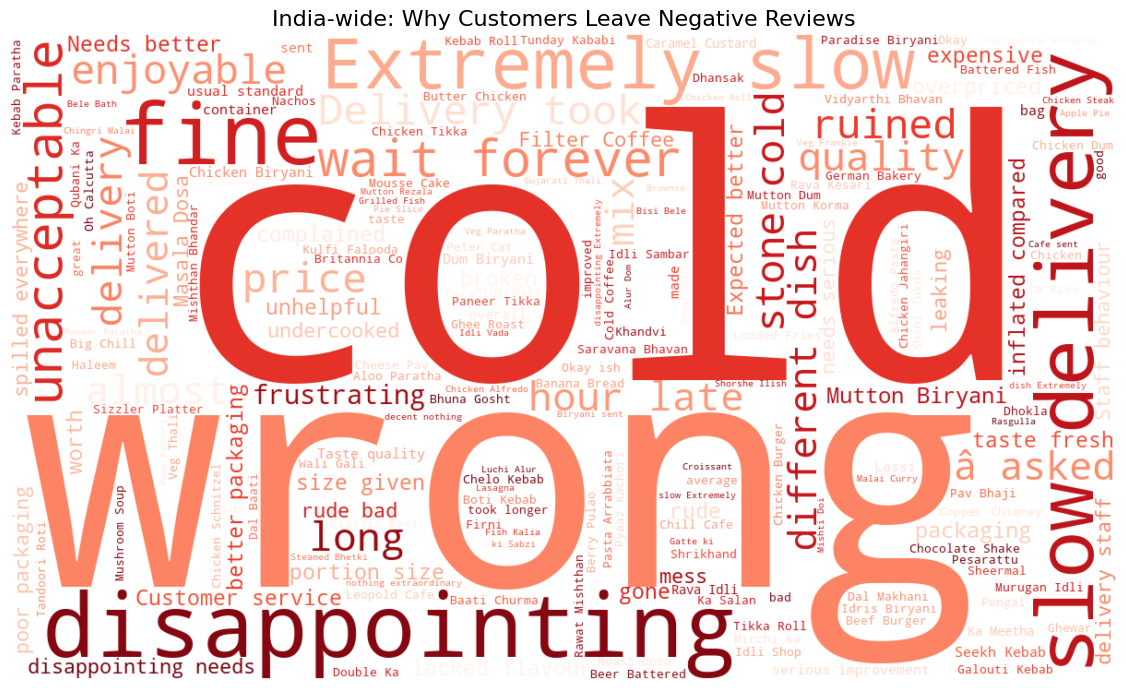

Chennai + Mumbai combined — complaint breakdown:
complaint_category
late_delivery      21.6
cold_food          19.4
wrong_order        17.8
overpriced         10.0
taste_issue         9.9
rude_staff          9.2
packaging_issue     9.1
none                2.9
Name: proportion, dtype: float64


In [17]:
# National wordcloud across ALL unhappy reviews, any restaurant, any city
national_unhappy_text = " ".join(unhappy_all["review_text"])

national_stopwords = STOPWORDS.union({
    "ordered", "order", "time", "item", "food", "experience", "meal",
    "arrived", "arrival", "reached", "received", "completely", "entirely",
    "quite", "way", "got", "something", "now", "day", "everything",
    "will", "go", "feel", "felt", "restaurant"
}).union(set(df["restaurant_name"].str.lower()))

plt.figure(figsize=(12, 7))
wc_national = WordCloud(width=1200, height=700, background_color="white",
                         colormap="Reds", stopwords=national_stopwords).generate(national_unhappy_text)
plt.imshow(wc_national, interpolation="bilinear")
plt.title("India-wide: Why Customers Leave Negative Reviews", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

# Chennai + Mumbai specifically, since they stand out on rejection rate
problem_cities = df[df["city"].isin(["Chennai", "Mumbai"])]
problem_summary = problem_cities[problem_cities["rating"] <= 2]["complaint_category"].value_counts(normalize=True) * 100
print("Chennai + Mumbai combined — complaint breakdown:")
print(problem_summary.round(1))